In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Folder containing the datasets
DATA_DIR = Path(r"C:\Users\Ademe\Desktop\freight-rate-prediction\data")

# Load datasets
train = pd.read_csv(DATA_DIR / "train-test.csv")
validation = pd.read_csv(DATA_DIR / "validation.csv")
december = pd.read_csv(DATA_DIR / "december-chart-inputs.csv")

# Inspect datasets
print("Training shape:", train.shape)
print("Validation shape:", validation.shape)
print("December shape:", december.shape)

display(train.head())
train.info()

Training shape: (48000, 14)
Validation shape: (12000, 13)
December shape: (31, 7)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [3]:
# Missing values
missing = pd.DataFrame({
    "Missing count": train.isna().sum(),
    "Missing %": train.isna().mean() * 100
})

display(missing[missing["Missing count"] > 0])

# Duplicate rows
print("Duplicate rows:", train.duplicated().sum())

# Invalid weights
print("Negative weights:", (train["weight"] < 0).sum())

# Target statistics
display(train["posted_rate"].describe())

,Missing count,Missing %
weight,300,0.625000
market_index,374,0.779167


Duplicate rows: 0
Negative weights: 292


count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
25%       1251.555000
50%       2030.760000
75%       3330.750000
max      25533.000000
Name: posted_rate, dtype: float64

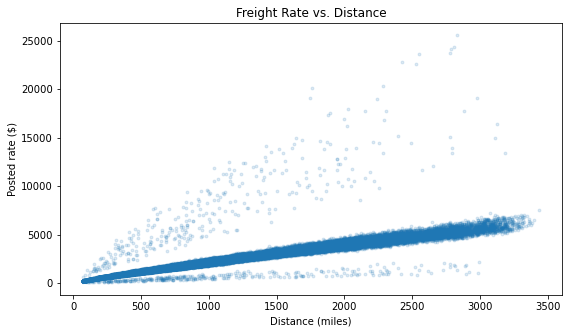

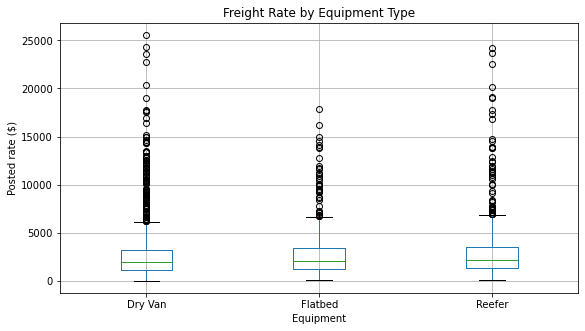

In [5]:
plt.figure(figsize=(9, 5))

plt.scatter(
    train["distance"],
    train["posted_rate"],
    alpha=0.15,
    s=8
)

plt.xlabel("Distance (miles)")
plt.ylabel("Posted rate ($)")
plt.title("Freight Rate vs. Distance")
plt.show()

train.boxplot(
    column="posted_rate",
    by="equipment",
    figsize=(9, 5)
)

plt.title("Freight Rate by Equipment Type")
plt.suptitle("")
plt.xlabel("Equipment")
plt.ylabel("Posted rate ($)")
plt.show()

In [7]:
train["date"] = pd.to_datetime(train["date"])

train["month"] = train["date"].dt.to_period("M")

train["rate_per_mile"] = train["posted_rate"] / train["distance"]

monthly = train.groupby("month").apply(
    lambda group: pd.Series({
        "correlation": group["rate_per_mile"].corr(
            group["quote_signal"]
        ),
        "mean_rate_per_mile": group["rate_per_mile"].mean(),
        "mean_quote_signal": group["quote_signal"].mean()
    })
)

display(monthly)

,correlation,mean_rate_per_mile,mean_quote_signal
month,,,
2025-01,0.446703,2.100221,2.068436
2025-02,0.479042,2.122885,2.097130
2025-03,0.485842,2.206132,2.179539
2025-04,-0.471742,2.210309,1.963388
2025-05,-0.459230,2.260106,1.912829
2025-06,0.476632,2.332484,2.296007
2025-07,-0.468345,2.255952,1.922997
2025-08,-0.013595,2.188584,2.052200
2025-09,0.481437,2.229725,2.199785


count    48000.000000
mean         2.215347
std          0.583887
min          0.333709
1%           1.673521
5%           1.807533
50%          2.145348
95%          2.735925
99%          3.176940
max         14.125294
Name: rate_per_mile, dtype: float64


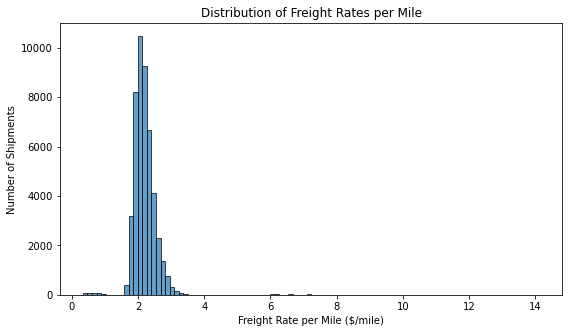

In [9]:
train["rate_per_mile"] = train["posted_rate"] / train["distance"]

print(train["rate_per_mile"].describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
))

plt.figure(figsize=(9, 5))

plt.hist(
    train["rate_per_mile"],
    bins=100,
    edgecolor="black",
    alpha=0.7
)

plt.xlabel("Freight Rate per Mile ($/mile)")
plt.ylabel("Number of Shipments")
plt.title("Distribution of Freight Rates per Mile")
plt.show()



In [10]:
low_rates = train[train["rate_per_mile"] < 1]
high_rates = train[train["rate_per_mile"] > 5]

print("Low-rate shipments:", len(low_rates))
print("High-rate shipments:", len(high_rates))

display(low_rates.head(10))
display(high_rates.head(10))

print("Low rates by month:")
display(low_rates["month"].value_counts().sort_index())

print("High rates by month:")
display(high_rates["month"].value_counts().sort_index())



Low-rate shipments: 329
High-rate shipments: 317


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,month,rate_per_mile
50,TR-000051,Los Angeles,Green Bay,28.56624,-116.70249,44.30296,-87.52871,2202.5,Reefer,26740.0,2025-01-01,1.00748,1.86794,1243.45,2025-01,0.564563
190,TR-000191,Tampa,Milwaukee,28.35765,-86.94782,39.62180,-88.48008,919.8,Dry Van,33053.0,2025-01-02,1.01568,1.95414,704.89,2025-01,0.766351
294,TR-000295,Greensboro,Syracuse,35.98195,-82.78379,42.80915,-76.89973,685.6,Dry Van,30959.0,2025-01-02,1.00393,1.89033,518.31,2025-01,0.755995
439,TR-000440,Richmond,Charleston,38.09122,-76.78906,34.15334,-79.74475,394.9,Dry Van,14768.0,2025-01-03,0.93596,2.07056,276.27,2025-01,0.699595
508,TR-000509,Las Vegas,Grand Rapids,33.22353,-115.24994,43.43800,-86.29173,1976.4,Flatbed,28233.0,2025-01-04,0.86314,1.82202,699.41,2025-01,0.353881
872,TR-000873,Cincinnati,Lexington,37.15706,-86.77499,36.99152,-84.99876,144.0,Dry Van,13535.0,2025-01-06,0.76351,2.35079,67.80,2025-01,0.470833
1027,TR-001028,Dallas,Fort Wayne,31.83025,-94.38343,41.31561,-85.36206,970.6,Dry Van,30362.0,2025-01-07,0.90312,1.88725,473.34,2025-01,0.487678
1160,TR-001161,Tucson,Oklahoma City,30.92733,-113.23037,31.88294,-98.58097,1012.6,Reefer,29209.0,2025-01-08,0.97099,2.24741,659.89,2025-01,0.651679
1351,TR-001352,Tulsa,Tucson,33.45894,-94.78556,30.92733,-113.23037,1260.0,Dry Van,10913.0,2025-01-09,1.03206,1.91751,882.08,2025-01,0.700063
1489,TR-001490,Chattanooga,Houston,35.29792,-87.18651,30.71157,-94.76550,647.0,Dry Van,37165.0,2025-01-10,0.95286,2.19564,438.53,2025-01,0.677790


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,month,rate_per_mile
388,TR-000389,Corpus Christi,Chattanooga,28.61374,-95.89569,35.29792,-87.18651,823.0,Flatbed,39556.0,2025-01-03,0.92409,2.22467,5485.49,2025-01,6.665237
469,TR-000470,Phoenix,Jacksonville,28.75668,-115.87725,31.98691,-84.48897,2154.3,Dry Van,22509.0,2025-01-04,0.84517,1.76215,10854.69,2025-01,5.038616
785,TR-000786,Kansas City,Charleston,39.41104,-91.12450,34.15334,-79.74475,861.5,Dry Van,28959.0,2025-01-06,0.83097,1.91323,4587.83,2025-01,5.325398
870,TR-000871,Tulsa,Baton Rouge,33.45894,-94.78556,30.50134,-92.65374,305.6,Reefer,26447.0,2025-01-06,0.80857,2.64181,4069.24,2025-01,13.315576
1149,TR-001150,Houston,Baton Rouge,30.71157,-94.76550,30.50134,-92.65374,170.3,Flatbed,28954.0,2025-01-08,0.97019,2.77328,1359.60,2025-01,7.983558
1175,TR-001176,Tucson,Phoenix,30.92733,-113.23037,28.75668,-115.87725,260.5,Dry Van,26547.0,2025-01-08,0.96147,2.24710,1609.22,2025-01,6.177428
1329,TR-001330,Harrisburg,Tulsa,39.71695,-78.12481,33.45894,-94.78556,1190.5,Dry Van,28538.0,2025-01-09,0.98010,1.87616,7100.73,2025-01,5.964494
1415,TR-001416,Montgomery,Birmingham,31.37602,-86.10743,33.45794,-86.72789,198.2,Reefer,25383.0,2025-01-09,0.99663,2.66449,2509.96,2025-01,12.663774
1417,TR-001418,Dallas,Atlanta,31.83025,-94.38343,34.84933,-86.28940,613.6,Flatbed,22461.0,2025-01-09,1.00981,2.25857,4485.75,2025-01,7.310544
1466,TR-001467,Los Angeles,Syracuse,28.56624,-116.70249,42.80915,-76.89973,2786.0,Reefer,30322.0,2025-01-10,0.98678,1.85370,24140.21,2025-01,8.664828


Low rates by month:


2025-01    40
2025-02    26
2025-03    37
2025-04    36
2025-05    36
2025-06    22
2025-07    29
2025-08    33
2025-09    30
2025-10    40
Freq: M, Name: month, dtype: int64

High rates by month:


2025-01    37
2025-02    27
2025-03    30
2025-04    28
2025-05    25
2025-06    36
2025-07    35
2025-08    32
2025-09    29
2025-10    38
Freq: M, Name: month, dtype: int64

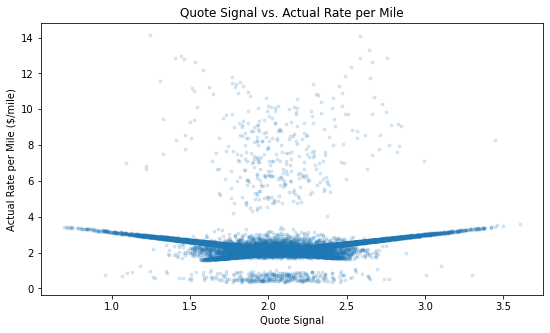

In [11]:
plt.figure(figsize=(9, 5))

plt.scatter(
    train["quote_signal"],
    train["rate_per_mile"],
    alpha=0.15,
    s=8
)

plt.xlabel("Quote Signal")
plt.ylabel("Actual Rate per Mile ($/mile)")
plt.title("Quote Signal vs. Actual Rate per Mile")
plt.show()

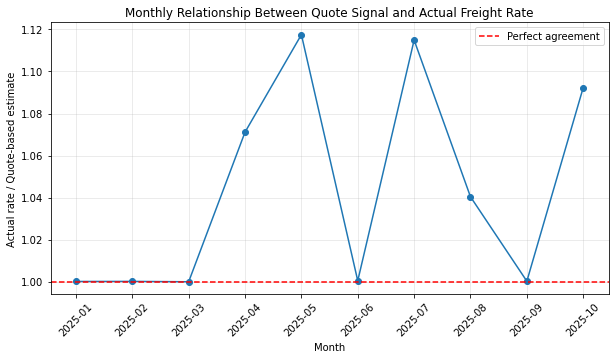

In [12]:
# Ratio between actual and quote-based rate
train["quote_ratio"] = (
    train["posted_rate"] /
    (train["distance"] * train["quote_signal"])
)

# Median ratio for each month
monthly_ratio = train.groupby("month")["quote_ratio"].median()

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_ratio.index.astype(str),
    monthly_ratio.values,
    marker="o"
)

plt.axhline(
    y=1,
    linestyle="--",
    color="red",
    label="Perfect agreement"
)

plt.xlabel("Month")
plt.ylabel("Actual rate / Quote-based estimate")
plt.title("Monthly Relationship Between Quote Signal and Actual Freight Rate")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

count    47626.000000
mean         1.083387
std          0.168091
min          0.676390
25%          0.949670
50%          1.055800
75%          1.219590
max          1.467780
Name: market_index, dtype: float64


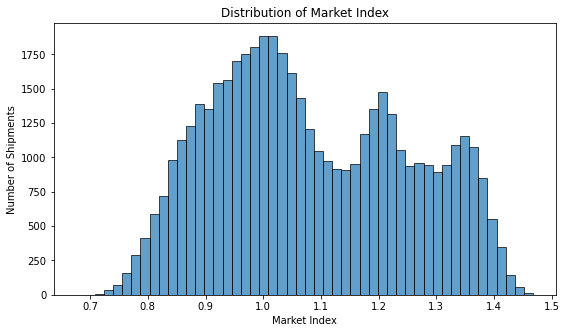

,market_index,quote_signal,rate_per_mile,quote_ratio
market_index,1.000,-0.068,0.083,0.124
quote_signal,-0.068,1.000,0.049,-0.483
rate_per_mile,0.083,0.049,1.000,0.815
quote_ratio,0.124,-0.483,0.815,1.000


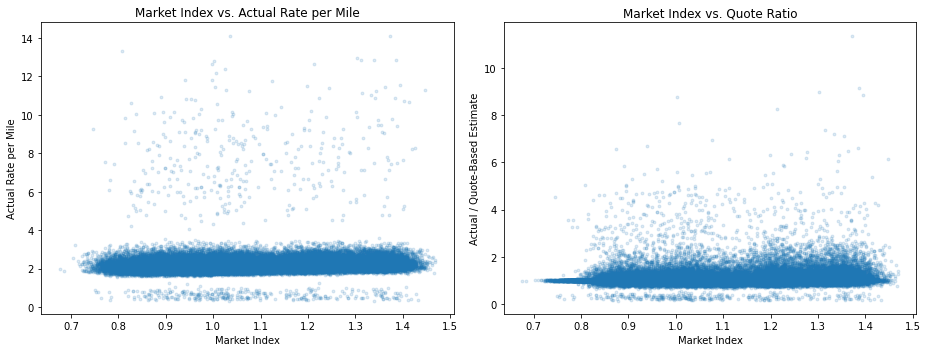

,mean_market_index,mean_rate_per_mile,median_quote_ratio
month,,,
2025-01,0.927,2.100,1.000
2025-02,0.996,2.123,1.000
2025-03,1.073,2.206,1.000
2025-04,1.208,2.210,1.071
2025-05,1.301,2.260,1.118
2025-06,1.280,2.332,1.000
2025-07,1.201,2.256,1.115
2025-08,0.981,2.189,1.040
2025-09,0.893,2.230,1.000


In [15]:
print(train["market_index"].describe())

plt.figure(figsize=(9, 5))

plt.hist(
    train["market_index"].dropna(),
    bins=50,
    edgecolor="black",
    alpha=0.7
)

plt.xlabel("Market Index")
plt.ylabel("Number of Shipments")
plt.title("Distribution of Market Index")
plt.show()

columns = [
    "market_index",
    "quote_signal",
    "rate_per_mile",
    "quote_ratio"
]

display(train[columns].corr().round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Market index versus actual rate per mile
axes[0].scatter(
    train["market_index"],
    train["rate_per_mile"],
    alpha=0.15,
    s=8
)

axes[0].set_xlabel("Market Index")
axes[0].set_ylabel("Actual Rate per Mile")
axes[0].set_title("Market Index vs. Actual Rate per Mile")

# Market index versus quote ratio
axes[1].scatter(
    train["market_index"],
    train["quote_ratio"],
    alpha=0.15,
    s=8
)

axes[1].set_xlabel("Market Index")
axes[1].set_ylabel("Actual / Quote-Based Estimate")
axes[1].set_title("Market Index vs. Quote Ratio")

plt.tight_layout()
plt.show()

monthly_market = train.groupby("month").agg(
    mean_market_index=("market_index", "mean"),
    mean_rate_per_mile=("rate_per_mile", "mean"),
    median_quote_ratio=("quote_ratio", "median")
)

display(monthly_market.round(3))

,count,mean,median,std
equipment,,,,
Dry Van,27202,2.115,2.046,0.538
Flatbed,8753,2.295,2.220,0.610
Reefer,12045,2.383,2.312,0.615


<Figure size 648x360 with 0 Axes>

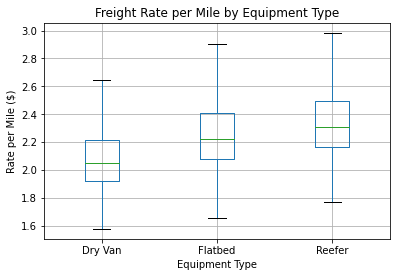

               weight  posted_rate  rate_per_mile
weight          1.000        0.042          0.093
posted_rate     0.042        1.000          0.003
rate_per_mile   0.093        0.003          1.000


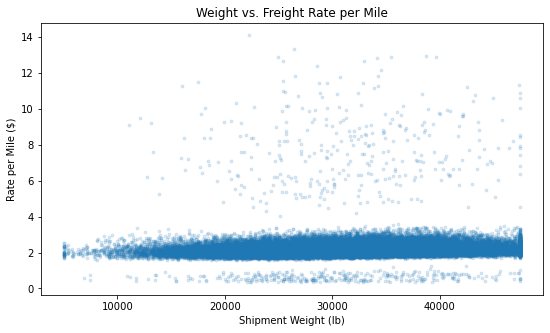

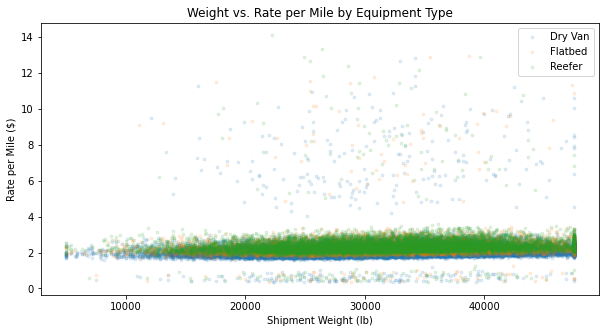

In [16]:
# Freight rate per mile by equipment type
equipment_stats = train.groupby("equipment")["rate_per_mile"].agg(
    ["count", "mean", "median", "std"]
)

display(equipment_stats.round(3))

# Visualize rate per mile by equipment
plt.figure(figsize=(9, 5))

train.boxplot(
    column="rate_per_mile",
    by="equipment",
    showfliers=False
)

plt.title("Freight Rate per Mile by Equipment Type")
plt.suptitle("")
plt.xlabel("Equipment Type")
plt.ylabel("Rate per Mile ($)")
plt.show()

# Only valid positive weights for exploration
valid_weight = train[
    train["weight"].notna() &
    (train["weight"] > 0)
].copy()

# Correlations
print(
    valid_weight[
        ["weight", "posted_rate", "rate_per_mile"]
    ].corr().round(3)
)

# Visualize weight vs. rate per mile
plt.figure(figsize=(9, 5))

plt.scatter(
    valid_weight["weight"],
    valid_weight["rate_per_mile"],
    alpha=0.15,
    s=8
)

plt.xlabel("Shipment Weight (lb)")
plt.ylabel("Rate per Mile ($)")
plt.title("Weight vs. Freight Rate per Mile")
plt.show()

# Weight vs. rate per mile, grouped by equipment
fig, ax = plt.subplots(figsize=(10, 5))

for equipment, group in valid_weight.groupby("equipment"):
    ax.scatter(
        group["weight"],
        group["rate_per_mile"],
        alpha=0.12,
        s=8,
        label=equipment
    )

ax.set_xlabel("Shipment Weight (lb)")
ax.set_ylabel("Rate per Mile ($)")
ax.set_title("Weight vs. Rate per Mile by Equipment Type")
ax.legend()

plt.show()

In [17]:
train["date"] = pd.to_datetime(train["date"])

# Expanding-window validation
folds = [
    ("2025-04-30", "2025-05-01", "2025-06-30"),
    ("2025-06-30", "2025-07-01", "2025-08-31"),
    ("2025-08-31", "2025-09-01", "2025-10-31"),
]

for i, (train_end, val_start, val_end) in enumerate(folds, 1):

    train_mask = train["date"] <= train_end

    val_mask = (
        (train["date"] >= val_start) &
        (train["date"] <= val_end)
    )

    train_fold = train.loc[train_mask]
    val_fold = train.loc[val_mask]

    print(f"Fold {i}")
    print(f"Training samples: {len(train_fold):,}")
    print(f"Validation samples: {len(val_fold):,}")
    print()

Fold 1
Training samples: 19,110
Validation samples: 9,696

Fold 2
Training samples: 28,806
Validation samples: 9,671

Fold 3
Training samples: 38,477
Validation samples: 9,523



In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true)) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape
    }

folds = [
    ("2025-04-30", "2025-05-01", "2025-06-30"),
    ("2025-06-30", "2025-07-01", "2025-08-31"),
    ("2025-08-31", "2025-09-01", "2025-10-31"),
]

results = []

for i, (train_end, val_start, val_end) in enumerate(folds, 1):

    # Chronological split
    train_fold = train[train["date"] <= train_end]

    val_fold = train[
        (train["date"] >= val_start) &
        (train["date"] <= val_end)
    ]

    y_true = val_fold["posted_rate"]

    # Baseline 1: Historical average rate per mile
    avg_rate_per_mile = train_fold["rate_per_mile"].mean()

    pred_avg = val_fold["distance"] * avg_rate_per_mile

    # Baseline 2: Quote-based estimate
    pred_quote = val_fold["distance"] * val_fold["quote_signal"]

    # Evaluate both baselines
    for model_name, predictions in [
        ("Average rate/mile", pred_avg),
        ("Quote signal", pred_quote)
    ]:
        metrics = evaluate(y_true, predictions)

        results.append({
            "Fold": i,
            "Model": model_name,
            **metrics
        })

baseline_results = pd.DataFrame(results)

display(baseline_results.round(2))

summary = baseline_results.groupby("Model")[
    ["MAE", "RMSE", "WAPE (%)"]
].mean()

display(summary.round(2))

,Fold,Model,MAE,RMSE,WAPE (%)
0,1,Average rate/mile,246.93,677.40,10.04
1,1,Quote signal,245.27,713.35,9.97
2,2,Average rate/mile,283.22,699.96,11.91
3,2,Quote signal,367.29,753.96,15.45
4,3,Average rate/mile,290.60,709.45,12.15
5,3,Quote signal,246.02,711.80,10.28


,MAE,RMSE,WAPE (%)
Model,,,
Average rate/mile,273.58,695.60,11.37
Quote signal,286.20,726.37,11.90


In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

def prepare_features(df):
    df = df.copy()

    # Extract month from date
    df["date"] = pd.to_datetime(df["date"])
    df["month_num"] = df["date"].dt.month

    # Handle physically invalid weights
    df.loc[df["weight"] <= 0, "weight"] = np.nan

    # Engineered quote-based estimate
    df["quote_estimated_rate"] = (
        df["distance"] * df["quote_signal"]
    )

    return df

numerical_features = [
    "distance",
    "weight",
    "market_index",
    "quote_signal",
    "quote_estimated_rate",
    "month_num"
]

categorical_features = [
    "equipment",
    "pickup",
    "delivery"
]

# Numerical preprocessing
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

from sklearn.base import clone
import time

linear_results = []

for i, (train_end, val_start, val_end) in enumerate(folds, 1):

    # Chronological split
    train_fold = train[train["date"] <= train_end].copy()

    val_fold = train[
        (train["date"] >= val_start) &
        (train["date"] <= val_end)
    ].copy()

    # Feature engineering
    train_fold = prepare_features(train_fold)
    val_fold = prepare_features(val_fold)

    # Separate features and target
    X_train = train_fold[
        numerical_features + categorical_features
    ]

    y_train = train_fold["posted_rate"]

    X_val = val_fold[
        numerical_features + categorical_features
    ]

    y_val = val_fold["posted_rate"]

    # Fresh model for each fold
    model = clone(linear_model)

    start = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start

    # Predict
    predictions = model.predict(X_val)

    # Evaluate
    metrics = evaluate(y_val, predictions)

    linear_results.append({
        "Fold": i,
        "Model": "Linear Regression",
        **metrics,
        "Training time (s)": training_time
    })

linear_results = pd.DataFrame(linear_results)

display(linear_results.round(2))

comparison = pd.concat([
    baseline_results,
    linear_results.drop(columns=["Training time (s)"])
], ignore_index=True)

display(
    comparison.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(2)
)

display(
    comparison.groupby("Model")[
        ["MAE", "RMSE", "WAPE (%)"]
    ].mean().round(2)
)



,Fold,Model,MAE,RMSE,WAPE (%),Training time (s)
0,1,Linear Regression,157.85,645.56,6.42,0.05
1,2,Linear Regression,175.79,633.69,7.39,0.06
2,3,Linear Regression,142.06,637.90,5.94,0.08


Model,Average rate/mile,Linear Regression,Quote signal
Fold,,,
1,246.93,157.85,245.27
2,283.22,175.79,367.29
3,290.60,142.06,246.02


,MAE,RMSE,WAPE (%)
Model,,,
Average rate/mile,273.58,695.60,11.37
Linear Regression,158.57,639.05,6.58
Quote signal,286.20,726.37,11.90


In [23]:
print(
    f"Fold {i} - Non-positive predictions:",
    (predictions <= 0).sum()
)

normal_mask = (
    (val_fold["rate_per_mile"] >= 1) &
    (val_fold["rate_per_mile"] <= 5)
)

normal_mae = mean_absolute_error(
    y_val[normal_mask],
    predictions[normal_mask]
)

extreme_mae = mean_absolute_error(
    y_val[~normal_mask],
    predictions[~normal_mask]
)

print(f"Fold {i} - Normal MAE: ${normal_mae:.2f}")
print(f"Fold {i} - Extreme MAE: ${extreme_mae:.2f}")



Fold 3 - Non-positive predictions: 1
Fold 3 - Normal MAE: $89.96
Fold 3 - Extreme MAE: $3711.49


In [24]:
%pip install catboost

Note: you may need to restart the kernel to use updated packages.


In [26]:
from catboost import CatBoostRegressor
from sklearn.base import clone
import time

catboost_features = [
    "distance",
    "weight",
    "market_index",
    "quote_signal",
    "quote_estimated_rate",
    "month_num",
    "equipment",
    "pickup",
    "delivery",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon"
]

categorical_features = [
    "equipment",
    "pickup",
    "delivery"
]

def prepare_catboost_features(df):
    df = df.copy()

    # Extract month
    df["date"] = pd.to_datetime(df["date"])
    df["month_num"] = df["date"].dt.month

    # Treat invalid weights as missing
    df.loc[df["weight"] <= 0, "weight"] = np.nan

    # Quote-based estimated total rate
    df["quote_estimated_rate"] = (
        df["distance"] * df["quote_signal"]
    )

    return df


In [27]:

catboost_model = CatBoostRegressor(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    thread_count=-1
)


In [31]:
def evaluate_catboost_cv(model_template, train_data, folds):

    results = []

    for i, (train_end, val_start, val_end) in enumerate(folds, 1):

        # Chronological split
        train_fold = train_data[
            train_data["date"] <= train_end
        ].copy()

        val_fold = train_data[
            (train_data["date"] >= val_start) &
            (train_data["date"] <= val_end)
        ].copy()

        # Feature engineering
        train_fold = prepare_catboost_features(train_fold)
        val_fold = prepare_catboost_features(val_fold)

        X_train = train_fold[catboost_features]
        y_train = train_fold["posted_rate"]

        X_val = val_fold[catboost_features]
        y_val = val_fold["posted_rate"]

        # Fresh model for each fold
        model = clone(model_template)

        start = time.perf_counter()

        model.fit(
            X_train,
            y_train,
            cat_features=categorical_features
        )

        training_time = time.perf_counter() - start

        # Predictions
        predictions = model.predict(X_val)

        # Overall evaluation
        metrics = evaluate(y_val, predictions)

        # Normal vs. extreme shipments
        normal_mask = (
            (val_fold["rate_per_mile"] >= 1) &
            (val_fold["rate_per_mile"] <= 5)
        )

        normal_mae = mean_absolute_error(
            y_val[normal_mask],
            predictions[normal_mask]
        )

        extreme_mae = mean_absolute_error(
            y_val[~normal_mask],
            predictions[~normal_mask]
        )

        results.append({
            "Fold": i,
            "Model": "CatBoost",
            **metrics,
            "Normal MAE": normal_mae,
            "Extreme MAE": extreme_mae,
            "Non-positive": int((predictions <= 0).sum()),
            "Training time (s)": training_time
        })

    return pd.DataFrame(results)

In [29]:
catboost_results = evaluate_catboost_cv(
    catboost_model,
    train,
    folds
)

display(catboost_results.round(2))

catboost_summary = catboost_results[
    ["MAE", "RMSE", "WAPE (%)"]
].mean()

linear_summary = linear_results[
    ["MAE", "RMSE", "WAPE (%)"]
].mean()

comparison = pd.DataFrame({
    "Linear Regression": linear_summary,
    "CatBoost": catboost_summary
}).T

display(comparison.round(2))

fold_comparison = pd.DataFrame({
    "Linear Regression": linear_results.set_index("Fold")["MAE"],
    "CatBoost": catboost_results.set_index("Fold")["MAE"]
})

display(fold_comparison.round(2))



,Fold,Model,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Non-positive,Training time (s)
0,1,CatBoost,170.23,657.97,6.92,119.71,4236.38,1,31.27
1,2,CatBoost,152.64,634.90,6.42,102.21,3882.55,0,31.93
2,3,CatBoost,120.99,638.45,5.06,68.69,3704.32,0,33.98


,MAE,RMSE,WAPE (%)
Linear Regression,158.57,639.05,6.58
CatBoost,147.95,643.77,6.13


,Linear Regression,CatBoost
Fold,,
1,157.85,170.23
2,175.79,152.64
3,142.06,120.99


In [30]:
features_no_quote = [
    feature for feature in catboost_features
    if feature not in ["quote_signal", "quote_estimated_rate"]
]

print(features_no_quote)

['distance', 'weight', 'market_index', 'month_num', 'equipment', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon']


In [32]:
def evaluate_catboost_cv(model_template, train_data, folds, features, model_name):

    results = []

    for i, (train_end, val_start, val_end) in enumerate(folds, 1):

        # Chronological split
        train_fold = train_data[
            train_data["date"] <= train_end
        ].copy()

        val_fold = train_data[
            (train_data["date"] >= val_start) &
            (train_data["date"] <= val_end)
        ].copy()

        # Feature engineering
        train_fold = prepare_catboost_features(train_fold)
        val_fold = prepare_catboost_features(val_fold)

        X_train = train_fold[features]
        y_train = train_fold["posted_rate"]

        X_val = val_fold[features]
        y_val = val_fold["posted_rate"]

        # Fresh model for each fold
        model = clone(model_template)

        start = time.perf_counter()

        model.fit(
            X_train,
            y_train,
            cat_features=categorical_features
        )

        training_time = time.perf_counter() - start

        predictions = model.predict(X_val)

        metrics = evaluate(y_val, predictions)

        # Normal vs extreme shipments
        normal_mask = (
            (val_fold["rate_per_mile"] >= 1) &
            (val_fold["rate_per_mile"] <= 5)
        )

        normal_mae = mean_absolute_error(
            y_val[normal_mask],
            predictions[normal_mask]
        )

        extreme_mae = mean_absolute_error(
            y_val[~normal_mask],
            predictions[~normal_mask]
        )

        results.append({
            "Fold": i,
            "Model": model_name,
            **metrics,
            "Normal MAE": normal_mae,
            "Extreme MAE": extreme_mae,
            "Non-positive": int((predictions <= 0).sum()),
            "Training time (s)": training_time
        })

    return pd.DataFrame(results)

In [33]:
catboost_no_quote_results = evaluate_catboost_cv(
    model_template=catboost_model,
    train_data=train,
    folds=folds,
    features=features_no_quote,
    model_name="CatBoost (No Quote)"
)

display(catboost_no_quote_results.round(2))

,Fold,Model,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Non-positive,Training time (s)
0,1,CatBoost (No Quote),147.74,658.11,6.01,96.70,4255.43,1,31.86
1,2,CatBoost (No Quote),161.50,635.24,6.79,111.26,3877.75,0,32.02
2,3,CatBoost (No Quote),120.33,635.23,5.03,68.13,3696.49,0,32.34


In [34]:
comparison = pd.concat([
    catboost_results,
    catboost_no_quote_results
], ignore_index=True)

# MAE by fold
display(
    comparison.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(2)
)

# Average metrics
display(
    comparison.groupby("Model")[
        ["MAE", "RMSE", "WAPE (%)"]
    ].mean().round(2)
)

Model,CatBoost,CatBoost (No Quote)
Fold,,
1,170.23,147.74
2,152.64,161.50
3,120.99,120.33


,MAE,RMSE,WAPE (%)
Model,,,
CatBoost,147.95,643.77,6.13
CatBoost (No Quote),143.19,642.86,5.94


In [35]:
december_features = [
    "distance",
    "weight",
    "month_num",
    "equipment",
    "pickup",
    "delivery"
]

print(december_features)

['distance', 'weight', 'month_num', 'equipment', 'pickup', 'delivery']


In [36]:
def prepare_catboost_features(df):
    df = df.copy()

    # Date features
    df["date"] = pd.to_datetime(df["date"])
    df["month_num"] = df["date"].dt.month

    # Invalid weights are treated as missing
    df.loc[df["weight"] <= 0, "weight"] = np.nan

    # Only calculate quote estimate when available
    if "quote_signal" in df.columns:
        df["quote_estimated_rate"] = (
            df["distance"] * df["quote_signal"]
        )

    return df

catboost_december_results = evaluate_catboost_cv(
    model_template=catboost_model,
    train_data=train,
    folds=folds,
    features=december_features,
    model_name="CatBoost (December Features)"
)

display(catboost_december_results.round(2))

catboost_comparison = pd.concat([
    catboost_results,
    catboost_no_quote_results,
    catboost_december_results
], ignore_index=True)

# MAE by fold
display(
    catboost_comparison.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(2)
)

# Overall metrics
display(
    catboost_comparison.groupby("Model")[
        ["MAE", "RMSE", "WAPE (%)"]
    ].mean().round(2)
)


,Fold,Model,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Non-positive,Training time (s)
0,1,CatBoost (December Features),147.71,645.33,6.01,97.14,4217.68,0,28.76
1,2,CatBoost (December Features),210.13,648.62,8.84,160.50,3880.94,0,30.14
2,3,CatBoost (December Features),124.66,638.62,5.21,72.35,3708.52,0,31.05


Model,CatBoost,CatBoost (December Features),CatBoost (No Quote)
Fold,,,
1,170.23,147.71,147.74
2,152.64,210.13,161.50
3,120.99,124.66,120.33


,MAE,RMSE,WAPE (%)
Model,,,
CatBoost,147.95,643.77,6.13
CatBoost (December Features),160.83,644.19,6.69
CatBoost (No Quote),143.19,642.86,5.94


In [37]:
catboost_mae_model = CatBoostRegressor(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function="MAE",
    random_seed=42,
    verbose=False,
    thread_count=-1
)

catboost_mae_results = evaluate_catboost_cv(
    model_template=catboost_mae_model,
    train_data=train,
    folds=folds,
    features=features_no_quote,
    model_name="CatBoost (MAE Loss)"
)

display(catboost_mae_results.round(2))

loss_comparison = pd.concat([
    catboost_no_quote_results,
    catboost_mae_results
], ignore_index=True)

display(
    loss_comparison.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(2)
)

display(
    loss_comparison.groupby("Model")[
        ["MAE", "RMSE", "WAPE (%)"]
    ].mean().round(2)
)

,Fold,Model,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Non-positive,Training time (s)
0,1,CatBoost (MAE Loss),119.97,638.17,4.88,68.88,4231.96,0,30.23
1,2,CatBoost (MAE Loss),120.45,621.13,5.07,69.66,3877.05,0,33.46
2,3,CatBoost (MAE Loss),116.88,636.49,4.89,64.46,3707.92,0,35.74


Model,CatBoost (MAE Loss),CatBoost (No Quote)
Fold,,
1,119.97,147.74
2,120.45,161.50
3,116.88,120.33


,MAE,RMSE,WAPE (%)
Model,,,
CatBoost (MAE Loss),119.10,631.93,4.94
CatBoost (No Quote),143.19,642.86,5.94


In [38]:
catboost_full_mae_results = evaluate_catboost_cv(
    model_template=catboost_mae_model,
    train_data=train,
    folds=folds,
    features=catboost_features,
    model_name="CatBoost (Full + MAE)"
)

display(catboost_full_mae_results.round(2))

mae_comparison = pd.concat([
    catboost_mae_results,
    catboost_full_mae_results
], ignore_index=True)

display(
    mae_comparison.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(2)
)

display(
    mae_comparison.groupby("Model")[
        ["MAE", "RMSE", "WAPE (%)"]
    ].mean().round(2)
)

,Fold,Model,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Non-positive,Training time (s)
0,1,CatBoost (Full + MAE),149.71,644.61,6.09,99.11,4221.45,0,30.93
1,2,CatBoost (Full + MAE),173.49,636.28,7.30,123.39,3878.91,0,33.26
2,3,CatBoost (Full + MAE),116.04,636.29,4.85,63.59,3709.06,0,35.65


Model,CatBoost (Full + MAE),CatBoost (MAE Loss)
Fold,,
1,149.71,119.97
2,173.49,120.45
3,116.04,116.88


,MAE,RMSE,WAPE (%)
Model,,,
CatBoost (Full + MAE),146.41,639.06,6.08
CatBoost (MAE Loss),119.10,631.93,4.94


In [39]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [40]:
import lightgbm as lgb
from lightgbm import LGBMRegressor
from sklearn.base import clone
import time

lightgbm_features = features_no_quote.copy()

print(lightgbm_features)

['distance', 'weight', 'market_index', 'month_num', 'equipment', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon']


In [42]:
lightgbm_model = LGBMRegressor(
    objective="regression_l1",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=40,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

def evaluate_lightgbm_cv(model_template, train_data, folds, features, model_name):

    results = []

    for i, (train_end, val_start, val_end) in enumerate(folds, 1):

        # Chronological split
        train_fold = train_data[
            train_data["date"] <= train_end
        ].copy()

        val_fold = train_data[
            (train_data["date"] >= val_start) &
            (train_data["date"] <= val_end)
        ].copy()

        # Feature engineering
        train_fold = prepare_catboost_features(train_fold)
        val_fold = prepare_catboost_features(val_fold)

        X_train = train_fold[features].copy()
        y_train = train_fold["posted_rate"]

        X_val = val_fold[features].copy()
        y_val = val_fold["posted_rate"]

        # Categorical preprocessing
        for col in categorical_features:

            # Categories determined from training data only
            X_train[col] = X_train[col].astype("category")

            # Apply the same categories to validation
            X_val[col] = pd.Categorical(
                X_val[col],
                categories=X_train[col].cat.categories
            )

        # Fresh model for each fold
        model = clone(model_template)

        start = time.perf_counter()

        model.fit(
            X_train,
            y_train,
            categorical_feature=categorical_features
        )

        training_time = time.perf_counter() - start

        # Predictions
        predictions = model.predict(X_val)

        # Overall metrics
        metrics = evaluate(y_val, predictions)

        # Normal vs. extreme shipments
        normal_mask = (
            (val_fold["rate_per_mile"] >= 1) &
            (val_fold["rate_per_mile"] <= 5)
        )

        normal_mae = mean_absolute_error(
            y_val[normal_mask],
            predictions[normal_mask]
        )

        extreme_mae = mean_absolute_error(
            y_val[~normal_mask],
            predictions[~normal_mask]
        )

        results.append({
            "Fold": i,
            "Model": model_name,
            **metrics,
            "Normal MAE": normal_mae,
            "Extreme MAE": extreme_mae,
            "Non-positive": int((predictions <= 0).sum()),
            "Training time (s)": training_time
        })

    return pd.DataFrame(results)

lightgbm_results = evaluate_lightgbm_cv(
    model_template=lightgbm_model,
    train_data=train,
    folds=folds,
    features=lightgbm_features,
    model_name="LightGBM (MAE)"
)

display(lightgbm_results.round(2))

model_comparison = pd.concat([
    catboost_mae_results,
    lightgbm_results
], ignore_index=True)

# MAE by fold
display(
    model_comparison.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(2)
)

# Average performance
display(
    model_comparison.groupby("Model")[
        ["MAE", "RMSE", "WAPE (%)"]
    ].mean().round(2)
)

display(
    model_comparison.groupby("Model")[
        ["Normal MAE", "Extreme MAE", "Training time (s)"]
    ].mean().round(2)
)

,Fold,Model,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Non-positive,Training time (s)
0,1,LightGBM (MAE),123.23,638.97,5.01,72.25,4226.41,0,1.78
1,2,LightGBM (MAE),106.63,620.18,4.48,55.57,3883.46,0,1.67
2,3,LightGBM (MAE),117.65,636.69,4.92,65.23,3709.07,0,1.94


Model,CatBoost (MAE Loss),LightGBM (MAE)
Fold,,
1,119.97,123.23
2,120.45,106.63
3,116.88,117.65


,MAE,RMSE,WAPE (%)
Model,,,
CatBoost (MAE Loss),119.10,631.93,4.94
LightGBM (MAE),115.84,631.94,4.80


,Normal MAE,Extreme MAE,Training time (s)
Model,,,
CatBoost (MAE Loss),67.67,3938.97,33.14
LightGBM (MAE),64.35,3939.64,1.79


In [43]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [44]:
import xgboost as xgb
from xgboost import XGBRegressor
from sklearn.base import clone
import time

print("XGBoost version:", xgb.__version__)

XGBoost version: 2.1.4


In [46]:
xgboost_model = XGBRegressor(
    objective="reg:absoluteerror",
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=1.0,
    tree_method="hist",
    enable_categorical=True,
    random_state=42,
    n_jobs=-1
)

def evaluate_xgboost_cv(model_template, train_data, folds, features, model_name):

    results = []

    for i, (train_end, val_start, val_end) in enumerate(folds, 1):

        # Chronological split
        train_fold = train_data[
            train_data["date"] <= train_end
        ].copy()

        val_fold = train_data[
            (train_data["date"] >= val_start) &
            (train_data["date"] <= val_end)
        ].copy()

        # Feature engineering
        train_fold = prepare_catboost_features(train_fold)
        val_fold = prepare_catboost_features(val_fold)

        # Separate features and target
        X_train = train_fold[features].copy()
        y_train = train_fold["posted_rate"]

        X_val = val_fold[features].copy()
        y_val = val_fold["posted_rate"]

        # Categorical preprocessing
        for col in categorical_features:

            # Determine categories from training data only
            X_train[col] = X_train[col].astype("category")

            # Use identical categories for validation
            X_val[col] = pd.Categorical(
                X_val[col],
                categories=X_train[col].cat.categories
            )

        # Fresh model for each fold
        model = clone(model_template)

        start = time.perf_counter()

        # Train
        model.fit(X_train, y_train)

        training_time = time.perf_counter() - start

        # Predict
        predictions = model.predict(X_val)

        # Overall evaluation
        metrics = evaluate(y_val, predictions)

        # Normal vs. extreme shipments
        normal_mask = (
            (val_fold["rate_per_mile"] >= 1) &
            (val_fold["rate_per_mile"] <= 5)
        )

        normal_mae = mean_absolute_error(
            y_val[normal_mask],
            predictions[normal_mask]
        )

        extreme_mae = mean_absolute_error(
            y_val[~normal_mask],
            predictions[~normal_mask]
        )

        results.append({
            "Fold": i,
            "Model": model_name,
            **metrics,
            "Normal MAE": normal_mae,
            "Extreme MAE": extreme_mae,
            "Non-positive": int((predictions <= 0).sum()),
            "Training time (s)": training_time
        })

    return pd.DataFrame(results)

xgboost_features = features_no_quote.copy()

xgboost_results = evaluate_xgboost_cv(
    model_template=xgboost_model,
    train_data=train,
    folds=folds,
    features=xgboost_features,
    model_name="XGBoost (MAE)"
)

display(xgboost_results.round(2))

boosting_comparison = pd.concat([
    catboost_mae_results,
    lightgbm_results,
    xgboost_results
], ignore_index=True)

display(
    boosting_comparison.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(2)
)

display(
    boosting_comparison.groupby("Model")[
        ["MAE", "RMSE", "WAPE (%)", "Training time (s)"]
    ].mean().round(2).sort_values("MAE")
)

display(
    boosting_comparison.groupby("Model")[
        ["Normal MAE", "Extreme MAE"]
    ].mean().round(2)
)



,Fold,Model,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Non-positive,Training time (s)
0,1,XGBoost (MAE),125.52,639.31,5.10,74.54,4227.76,0,5.87
1,2,XGBoost (MAE),111.93,620.84,4.71,60.93,3884.04,0,6.40
2,3,XGBoost (MAE),118.28,636.49,4.94,65.90,3707.17,0,8.26


Model,CatBoost (MAE Loss),LightGBM (MAE),XGBoost (MAE)
Fold,,,
1,119.97,123.23,125.52
2,120.45,106.63,111.93
3,116.88,117.65,118.28


,MAE,RMSE,WAPE (%),Training time (s)
Model,,,,
LightGBM (MAE),115.84,631.94,4.80,1.79
XGBoost (MAE),118.58,632.21,4.92,6.84
CatBoost (MAE Loss),119.10,631.93,4.94,33.14


,Normal MAE,Extreme MAE
Model,,
CatBoost (MAE Loss),67.67,3938.97
LightGBM (MAE),64.35,3939.64
XGBoost (MAE),67.13,3939.66


In [47]:
LOWER_RPM = 1.0
UPPER_RPM = 5.0

for i, (train_end, val_start, val_end) in enumerate(folds, 1):

    train_fold = train[train["date"] <= train_end]

    rpm = train_fold["posted_rate"] / train_fold["distance"]

    outlier_mask = (
        (rpm < LOWER_RPM) |
        (rpm > UPPER_RPM)
    )

    print(f"Fold {i}")
    print(f"Original training samples: {len(train_fold):,}")
    print(f"Outliers removed: {outlier_mask.sum():,}")
    print(f"Remaining samples: {(~outlier_mask).sum():,}")
    print()
    


Fold 1
Original training samples: 19,110
Outliers removed: 261
Remaining samples: 18,849

Fold 2
Original training samples: 28,806
Outliers removed: 380
Remaining samples: 28,426

Fold 3
Original training samples: 38,477
Outliers removed: 509
Remaining samples: 37,968



In [48]:
def evaluate_lightgbm_cv(
    model_template,
    train_data,
    folds,
    features,
    model_name,
    remove_outliers=False
):

    results = []

    for i, (train_end, val_start, val_end) in enumerate(folds, 1):

        # Chronological split
        train_fold = train_data[
            train_data["date"] <= train_end
        ].copy()

        val_fold = train_data[
            (train_data["date"] >= val_start) &
            (train_data["date"] <= val_end)
        ].copy()

        # Remove outliers from TRAINING data only
        if remove_outliers:

            rpm = train_fold["posted_rate"] / train_fold["distance"]

            valid_mask = (
                (rpm >= LOWER_RPM) &
                (rpm <= UPPER_RPM)
            )

            removed = (~valid_mask).sum()

            train_fold = train_fold.loc[valid_mask].copy()

            print(f"Fold {i}: Removed {removed} training outliers")

        # Feature engineering
        train_fold = prepare_catboost_features(train_fold)
        val_fold = prepare_catboost_features(val_fold)

        X_train = train_fold[features].copy()
        y_train = train_fold["posted_rate"]

        X_val = val_fold[features].copy()
        y_val = val_fold["posted_rate"]

        # Categorical preprocessing
        for col in categorical_features:

            X_train[col] = X_train[col].astype("category")

            X_val[col] = pd.Categorical(
                X_val[col],
                categories=X_train[col].cat.categories
            )

        # Fresh model
        model = clone(model_template)

        start = time.perf_counter()

        model.fit(
            X_train,
            y_train,
            categorical_feature=categorical_features
        )

        training_time = time.perf_counter() - start

        predictions = model.predict(X_val)

        # Overall metrics on ALL validation samples
        metrics = evaluate(y_val, predictions)

        # Diagnostic evaluation: normal vs. extreme
        val_rpm = y_val / val_fold["distance"]

        normal_mask = (
            (val_rpm >= LOWER_RPM) &
            (val_rpm <= UPPER_RPM)
        )

        normal_mae = mean_absolute_error(
            y_val[normal_mask],
            predictions[normal_mask]
        )

        extreme_mae = mean_absolute_error(
            y_val[~normal_mask],
            predictions[~normal_mask]
        )

        results.append({
            "Fold": i,
            "Model": model_name,
            **metrics,
            "Normal MAE": normal_mae,
            "Extreme MAE": extreme_mae,
            "Non-positive": int((predictions <= 0).sum()),
            "Training time (s)": training_time
        })

    return pd.DataFrame(results)

lightgbm_no_outliers_results = evaluate_lightgbm_cv(
    model_template=lightgbm_model,
    train_data=train,
    folds=folds,
    features=lightgbm_features,
    model_name="LightGBM (No Outliers)",
    remove_outliers=True
)

display(lightgbm_no_outliers_results.round(2))

outlier_comparison = pd.concat([
    lightgbm_results,
    lightgbm_no_outliers_results
], ignore_index=True
)

# MAE per fold
display(
    outlier_comparison.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(2)
)

# Average performance
display(
    outlier_comparison.groupby("Model")[
        ["MAE", "RMSE", "WAPE (%)"]
    ].mean().round(2)
)

# Normal vs extreme errors
display(
    outlier_comparison.groupby("Model")[
        ["Normal MAE", "Extreme MAE"]
    ].mean().round(2)
)



Fold 1: Removed 261 training outliers
Fold 2: Removed 380 training outliers
Fold 3: Removed 509 training outliers


,Fold,Model,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Non-positive,Training time (s)
0,1,LightGBM (No Outliers),122.66,638.38,4.99,71.66,4227.28,0,1.45
1,2,LightGBM (No Outliers),108.17,620.58,4.55,57.11,3885.41,0,1.81
2,3,LightGBM (No Outliers),117.98,636.90,4.93,65.57,3708.99,0,2.04


Model,LightGBM (MAE),LightGBM (No Outliers)
Fold,,
1,123.23,122.66
2,106.63,108.17
3,117.65,117.98


,MAE,RMSE,WAPE (%)
Model,,,
LightGBM (MAE),115.84,631.94,4.80
LightGBM (No Outliers),116.27,631.95,4.82


,Normal MAE,Extreme MAE
Model,,
LightGBM (MAE),64.35,3939.64
LightGBM (No Outliers),64.78,3940.56


In [49]:
def evaluate_target_strategy(
    model_template,
    train_data,
    folds,
    features,
    target_strategy="direct"
):
    results = []

    for i, (train_end, val_start, val_end) in enumerate(folds, 1):

        # Chronological split
        train_fold = train_data[
            train_data["date"] <= train_end
        ].copy()

        val_fold = train_data[
            (train_data["date"] >= val_start) &
            (train_data["date"] <= val_end)
        ].copy()

        # Feature engineering
        train_fold = prepare_catboost_features(train_fold)
        val_fold = prepare_catboost_features(val_fold)

        X_train = train_fold[features].copy()
        X_val = val_fold[features].copy()

        # Categorical preprocessing
        for col in categorical_features:
            X_train[col] = X_train[col].astype("category")

            X_val[col] = pd.Categorical(
                X_val[col],
                categories=X_train[col].cat.categories
            )

        # Define training target and sample weights
        if target_strategy == "direct":
            y_train = train_fold["posted_rate"]
            sample_weights = None

        elif target_strategy == "rpm":
            y_train = (
                train_fold["posted_rate"] /
                train_fold["distance"]
            )
            sample_weights = None

        elif target_strategy == "weighted_rpm":
            y_train = (
                train_fold["posted_rate"] /
                train_fold["distance"]
            )

            sample_weights = train_fold["distance"]

        else:
            raise ValueError("Unknown target strategy")

        # Train a fresh model
        model = clone(model_template)

        start = time.perf_counter()

        model.fit(
            X_train,
            y_train,
            sample_weight=sample_weights,
            categorical_feature=categorical_features
        )

        training_time = time.perf_counter() - start

        # Predict
        predictions = model.predict(X_val)

        # Convert RPM predictions to total freight rate
        if target_strategy in ["rpm", "weighted_rpm"]:
            predictions = predictions * val_fold["distance"].to_numpy()

        # Evaluate in DOLLARS for all strategies
        y_val = val_fold["posted_rate"]

        metrics = evaluate(y_val, predictions)

        # Normal vs. extreme shipments
        val_rpm = y_val / val_fold["distance"]

        normal_mask = (
            (val_rpm >= 1.0) &
            (val_rpm <= 5.0)
        )

        normal_mae = mean_absolute_error(
            y_val[normal_mask],
            predictions[normal_mask]
        )

        extreme_mae = mean_absolute_error(
            y_val[~normal_mask],
            predictions[~normal_mask]
        )

        results.append({
            "Fold": i,
            "Model": target_strategy,
            **metrics,
            "Normal MAE": normal_mae,
            "Extreme MAE": extreme_mae,
            "Non-positive": int((predictions <= 0).sum()),
            "Training time (s)": training_time
        })

    return pd.DataFrame(results)

lightgbm_rpm_results = evaluate_target_strategy(
    model_template=lightgbm_model,
    train_data=train,
    folds=folds,
    features=lightgbm_features,
    target_strategy="rpm"
)

display(lightgbm_rpm_results.round(2))

lightgbm_weighted_rpm_results = evaluate_target_strategy(
    model_template=lightgbm_model,
    train_data=train,
    folds=folds,
    features=lightgbm_features,
    target_strategy="weighted_rpm"
)

display(lightgbm_weighted_rpm_results.round(2))

# Original direct prediction results
direct_results = lightgbm_results.copy()
direct_results["Model"] = "direct"

# Combine all strategies
target_comparison = pd.concat([
    direct_results,
    lightgbm_rpm_results,
    lightgbm_weighted_rpm_results
], ignore_index=True)

display(
    target_comparison.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(2)
)

display(
    target_comparison.groupby("Model")[
        ["MAE", "RMSE", "WAPE (%)"]
    ].mean().round(2).sort_values("MAE")
)

display(
    target_comparison.groupby("Model")[
        ["Normal MAE", "Extreme MAE"]
    ].mean().round(2)
)



,Fold,Model,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Non-positive,Training time (s)
0,1,rpm,116.90,636.82,4.75,65.83,4227.27,0,1.44
1,2,rpm,112.73,620.67,4.74,61.79,3880.53,0,1.69
2,3,rpm,115.67,636.41,4.83,63.20,3710.49,0,1.96


,Fold,Model,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Non-positive,Training time (s)
0,1,weighted_rpm,119.47,637.13,4.86,68.41,4228.14,0,3.60
1,2,weighted_rpm,106.82,620.01,4.49,55.82,3879.36,0,5.98
2,3,weighted_rpm,116.19,636.32,4.86,63.74,3709.32,0,9.13


Model,direct,rpm,weighted_rpm
Fold,,,
1,123.23,116.90,119.47
2,106.63,112.73,106.82
3,117.65,115.67,116.19


,MAE,RMSE,WAPE (%)
Model,,,
weighted_rpm,114.16,631.15,4.74
rpm,115.10,631.30,4.78
direct,115.84,631.94,4.80


,Normal MAE,Extreme MAE
Model,,
direct,64.35,3939.64
rpm,63.60,3939.43
weighted_rpm,62.66,3938.94


In [50]:
def engineer_features(
    df,
    add_temporal=False,
    add_geographic=False
):
    df = df.copy()

    # -------------------------
    # Basic preprocessing
    # -------------------------

    df["date"] = pd.to_datetime(df["date"])

    df["month_num"] = df["date"].dt.month

    # Treat physically invalid weights as missing
    df.loc[df["weight"] <= 0, "weight"] = np.nan

    # -------------------------
    # Temporal features
    # -------------------------

    if add_temporal:

        df["day_of_week"] = df["date"].dt.dayofweek

        df["day_of_month"] = df["date"].dt.day

        df["days_since_start"] = (
            df["date"] - pd.Timestamp("2025-01-01")
        ).dt.days

    # -------------------------
    # Geographic features
    # -------------------------

    if add_geographic:

        df["latitude_difference"] = (
            df["delivery_lat"] - df["pickup_lat"]
        )

        df["longitude_difference"] = (
            df["delivery_lon"] - df["pickup_lon"]
        )

        # Convert coordinates to radians
        lat1 = np.radians(df["pickup_lat"])
        lon1 = np.radians(df["pickup_lon"])

        lat2 = np.radians(df["delivery_lat"])
        lon2 = np.radians(df["delivery_lon"])

        dlat = lat2 - lat1
        dlon = lon2 - lon1

        # Haversine formula
        a = (
            np.sin(dlat / 2) ** 2
            + np.cos(lat1)
            * np.cos(lat2)
            * np.sin(dlon / 2) ** 2
        )

        a = np.clip(a, 0, 1)

        c = 2 * np.arcsin(np.sqrt(a))

        # Earth's approximate radius in miles
        earth_radius_miles = 3958.8

        df["haversine_distance"] = (
            earth_radius_miles * c
        )

    return df

# Original features used by our best LightGBM model
base_features = lightgbm_features.copy()

# New temporal features
temporal_features = [
    "day_of_week",
    "day_of_month",
    "days_since_start"
]

# New geographic features
geographic_features = [
    "latitude_difference",
    "longitude_difference",
    "haversine_distance"
]

# Four experimental configurations
feature_configs = {
    "Baseline": {
        "features": base_features,
        "temporal": False,
        "geographic": False
    },

    "Temporal": {
        "features": base_features + temporal_features,
        "temporal": True,
        "geographic": False
    },

    "Geographic": {
        "features": base_features + geographic_features,
        "temporal": False,
        "geographic": True
    },

    "Combined": {
        "features": (
            base_features
            + temporal_features
            + geographic_features
        ),
        "temporal": True,
        "geographic": True
    }
}

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import time


def evaluate_feature_experiment(
    model_template,
    train_data,
    folds,
    features,
    model_name,
    add_temporal=False,
    add_geographic=False
):

    results = []

    for i, (train_end, val_start, val_end) in enumerate(folds, 1):

        # -------------------------
        # Chronological split
        # -------------------------

        train_fold = train_data[
            train_data["date"] <= train_end
        ].copy()

        val_fold = train_data[
            (train_data["date"] >= val_start) &
            (train_data["date"] <= val_end)
        ].copy()

        # -------------------------
        # Feature engineering
        # -------------------------

        train_fold = engineer_features(
            train_fold,
            add_temporal=add_temporal,
            add_geographic=add_geographic
        )

        val_fold = engineer_features(
            val_fold,
            add_temporal=add_temporal,
            add_geographic=add_geographic
        )

        # -------------------------
        # Features and target
        # -------------------------

        X_train = train_fold[features].copy()
        X_val = val_fold[features].copy()

        # Predict rate per mile
        y_train = (
            train_fold["posted_rate"]
            / train_fold["distance"]
        )

        # Weight errors according to distance
        sample_weights = train_fold["distance"]

        # Actual total rates for evaluation
        y_val = val_fold["posted_rate"]

        # -------------------------
        # Categorical preprocessing
        # -------------------------

        for col in categorical_features:

            X_train[col] = X_train[col].astype("category")

            X_val[col] = pd.Categorical(
                X_val[col],
                categories=X_train[col].cat.categories
            )

        # -------------------------
        # Model training
        # -------------------------

        model = clone(model_template)

        start = time.perf_counter()

        model.fit(
            X_train,
            y_train,
            sample_weight=sample_weights,
            categorical_feature=categorical_features
        )

        training_time = time.perf_counter() - start

        # -------------------------
        # Prediction
        # -------------------------

        predicted_rpm = model.predict(X_val)

        predictions = (
            predicted_rpm
            * val_fold["distance"].to_numpy()
        )

        # -------------------------
        # Evaluation
        # -------------------------

        metrics = evaluate(y_val, predictions)

        val_rpm = (
            y_val / val_fold["distance"]
        )

        normal_mask = (
            (val_rpm >= 1.0)
            & (val_rpm <= 5.0)
        )

        normal_mae = mean_absolute_error(
            y_val[normal_mask],
            predictions[normal_mask]
        )

        extreme_mae = mean_absolute_error(
            y_val[~normal_mask],
            predictions[~normal_mask]
        )

        results.append({
            "Fold": i,
            "Model": model_name,
            **metrics,
            "Normal MAE": normal_mae,
            "Extreme MAE": extreme_mae,
            "Non-positive": int((predictions <= 0).sum()),
            "Training time (s)": training_time
        })

    return pd.DataFrame(results)

feature_experiment_results = []

for name, config in feature_configs.items():

    print(f"Running experiment: {name}")

    results = evaluate_feature_experiment(
        model_template=lightgbm_model,
        train_data=train,
        folds=folds,
        features=config["features"],
        model_name=name,
        add_temporal=config["temporal"],
        add_geographic=config["geographic"]
    )

    feature_experiment_results.append(results)

feature_experiment_results = pd.concat(
    feature_experiment_results,
    ignore_index=True
)

display(feature_experiment_results.round(2))

mae_comparison = feature_experiment_results.pivot(
    index="Fold",
    columns="Model",
    values="MAE"
)

display(mae_comparison.round(2))

feature_summary = (
    feature_experiment_results
    .groupby("Model")[
        [
            "MAE",
            "RMSE",
            "WAPE (%)",
            "Normal MAE",
            "Extreme MAE",
            "Training time (s)"
        ]
    ]
    .mean()
    .sort_values("MAE")
)

display(feature_summary.round(2))

Running experiment: Baseline
Running experiment: Temporal
Running experiment: Geographic
Running experiment: Combined


,Fold,Model,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Non-positive,Training time (s)
0,1,Baseline,119.47,637.13,4.86,68.41,4228.14,0,3.78
1,2,Baseline,106.82,620.01,4.49,55.82,3879.36,0,6.08
2,3,Baseline,116.19,636.32,4.86,63.74,3709.32,0,8.97
3,1,Temporal,124.56,638.22,5.07,73.57,4228.17,0,4.03
4,2,Temporal,146.40,626.71,6.16,95.87,3884.50,0,6.52
5,3,Temporal,115.40,635.81,4.82,62.96,3708.00,0,8.04
6,1,Geographic,119.39,637.70,4.86,68.31,4230.02,0,3.92
7,2,Geographic,104.70,620.34,4.40,53.64,3881.50,0,6.89
8,3,Geographic,116.10,636.27,4.85,63.64,3710.10,0,10.13
9,1,Combined,123.72,638.03,5.03,72.74,4227.13,0,4.29


Model,Baseline,Combined,Geographic,Temporal
Fold,,,,
1,119.47,123.72,119.39,124.56
2,106.82,150.22,104.70,146.40
3,116.19,115.26,116.10,115.40


,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Training time (s)
Model,,,,,,
Geographic,113.40,631.44,4.70,61.87,3940.54,6.98
Baseline,114.16,631.15,4.74,62.66,3938.94,6.27
Temporal,128.79,633.58,5.35,77.47,3940.22,6.20
Combined,129.73,633.67,5.39,78.44,3939.29,7.11


In [52]:
def engineer_features_v2(
    df,
    add_geographic=True,
    weight_strategy="missing"
):
    df = df.copy()

    df["date"] = pd.to_datetime(df["date"])
    df["month_num"] = df["date"].dt.month

    # Weight handling
    if weight_strategy == "missing":
        df.loc[df["weight"] <= 0, "weight"] = np.nan

    elif weight_strategy == "absolute":
        df["weight"] = df["weight"].abs()

    elif weight_strategy == "original":
        pass

    elif weight_strategy == "missing_indicator":
        df["invalid_weight"] = (
            df["weight"].isna() |
            (df["weight"] <= 0)
        ).astype(int)

        df.loc[df["weight"] <= 0, "weight"] = np.nan

    else:
        raise ValueError("Unknown weight strategy")

    # Geographic features
    if add_geographic:

        df["latitude_difference"] = (
            df["delivery_lat"] - df["pickup_lat"]
        )

        df["longitude_difference"] = (
            df["delivery_lon"] - df["pickup_lon"]
        )

        lat1 = np.radians(df["pickup_lat"])
        lon1 = np.radians(df["pickup_lon"])

        lat2 = np.radians(df["delivery_lat"])
        lon2 = np.radians(df["delivery_lon"])

        dlat = lat2 - lat1
        dlon = lon2 - lon1

        a = (
            np.sin(dlat / 2) ** 2
            + np.cos(lat1)
            * np.cos(lat2)
            * np.sin(dlon / 2) ** 2
        )

        a = np.clip(a, 0, 1)

        df["haversine_distance"] = (
            3958.8 * 2 * np.arcsin(np.sqrt(a))
        )

    return df

weight_configs = {
    "Missing": {
        "weight_strategy": "missing",
        "features": base_features + geographic_features
    },

    "Absolute": {
        "weight_strategy": "absolute",
        "features": base_features + geographic_features
    },

    "Original": {
        "weight_strategy": "original",
        "features": base_features + geographic_features
    },

    "Missing + Indicator": {
        "weight_strategy": "missing_indicator",
        "features": (
            base_features
            + geographic_features
            + ["invalid_weight"]
        )
    }
}

def evaluate_weight_experiment(
    model_template,
    train_data,
    folds,
    features,
    model_name,
    weight_strategy="missing"
):
    results = []

    for i, (train_end, val_start, val_end) in enumerate(folds, 1):

        # 1. Chronological split
        train_fold = train_data[
            train_data["date"] <= train_end
        ].copy()

        val_fold = train_data[
            (train_data["date"] >= val_start) &
            (train_data["date"] <= val_end)
        ].copy()

        # 2. Feature engineering and weight cleaning
        train_fold = engineer_features_v2(
            train_fold,
            add_geographic=True,
            weight_strategy=weight_strategy
        )

        val_fold = engineer_features_v2(
            val_fold,
            add_geographic=True,
            weight_strategy=weight_strategy
        )

        # 3. Features
        X_train = train_fold[features].copy()
        X_val = val_fold[features].copy()

        # 4. Rate-per-mile target
        y_train = (
            train_fold["posted_rate"] /
            train_fold["distance"]
        )

        sample_weights = train_fold["distance"]

        y_val = val_fold["posted_rate"]

        # 5. Categorical preprocessing
        for col in categorical_features:

            X_train[col] = X_train[col].astype("category")

            X_val[col] = pd.Categorical(
                X_val[col],
                categories=X_train[col].cat.categories
            )

        # 6. Train model
        model = clone(model_template)

        start = time.perf_counter()

        model.fit(
            X_train,
            y_train,
            sample_weight=sample_weights,
            categorical_feature=categorical_features
        )

        training_time = time.perf_counter() - start

        # 7. Predict total freight rate
        predicted_rpm = model.predict(X_val)

        predictions = (
            predicted_rpm *
            val_fold["distance"].to_numpy()
        )

        # 8. Evaluation
        metrics = evaluate(y_val, predictions)

        val_rpm = y_val / val_fold["distance"]

        normal_mask = (
            (val_rpm >= 1.0) &
            (val_rpm <= 5.0)
        )

        normal_mae = mean_absolute_error(
            y_val[normal_mask],
            predictions[normal_mask]
        )

        extreme_mae = mean_absolute_error(
            y_val[~normal_mask],
            predictions[~normal_mask]
        )

        results.append({
            "Fold": i,
            "Model": model_name,
            **metrics,
            "Normal MAE": normal_mae,
            "Extreme MAE": extreme_mae,
            "Non-positive": int((predictions <= 0).sum()),
            "Training time (s)": training_time
        })

    return pd.DataFrame(results)

weight_results = []

for name, config in weight_configs.items():

    print(f"Testing: {name}")

    result = evaluate_weight_experiment(
        model_template=lightgbm_model,
        train_data=train,
        folds=folds,
        features=config["features"],
        model_name=name,
        weight_strategy=config["weight_strategy"]
    )

    weight_results.append(result)

weight_results = pd.concat(
    weight_results,
    ignore_index=True
)

# Average performance
display(
    weight_results.groupby("Model")[
        ["MAE", "RMSE", "WAPE (%)"]
    ].mean().round(2).sort_values("MAE")
)

# MAE by fold
display(
    weight_results.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(2)
)

Testing: Missing
Testing: Absolute
Testing: Original
Testing: Missing + Indicator


,MAE,RMSE,WAPE (%)
Model,,,
Missing,113.40,631.44,4.70
Missing + Indicator,113.40,631.44,4.70
Original,113.63,631.24,4.71
Absolute,113.78,631.46,4.72


Model,Absolute,Missing,Missing + Indicator,Original
Fold,,,,
1,119.93,119.39,119.39,119.47
2,105.63,104.70,104.70,105.49
3,115.78,116.10,116.10,115.94


In [53]:
from sklearn.model_selection import ParameterSampler

param_distributions = {
    "n_estimators": [500, 800, 1000, 1500],
    "learning_rate": [0.02, 0.03, 0.05, 0.08],
    "num_leaves": [15, 31, 63, 127],
    "max_depth": [-1, 5, 8, 12],
    "min_child_samples": [20, 40, 60, 100],
    "reg_lambda": [0.0, 0.5, 1.0, 5.0],
    "reg_alpha": [0.0, 0.1, 0.5, 1.0]
}

parameter_samples = list(
    ParameterSampler(
        param_distributions,
        n_iter=30,
        random_state=42
    )
)

print("Configurations to test:", len(parameter_samples))

from lightgbm import LGBMRegressor
import time

tuning_results = []

features = base_features + geographic_features

for idx, params in enumerate(parameter_samples, 1):

    print(f"Testing configuration {idx}/{len(parameter_samples)}")

    model = LGBMRegressor(
        objective="regression_l1",
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
        **params
    )

    cv_results = evaluate_weight_experiment(
        model_template=model,
        train_data=train,
        folds=folds,
        features=features,
        model_name=f"Config {idx}",
        weight_strategy="missing"
    )

    tuning_results.append({
        "Configuration": idx,
        **params,
        "MAE": cv_results["MAE"].mean(),
        "RMSE": cv_results["RMSE"].mean(),
        "WAPE (%)": cv_results["WAPE (%)"].mean(),
        "MAE std": cv_results["MAE"].std(),
        "Worst fold MAE": cv_results["MAE"].max()
    })

tuning_results = pd.DataFrame(tuning_results)

best_configs = tuning_results.sort_values("MAE")

display(best_configs.head(10).round(3))

print("Current model MAE: $113.40")

print(
    "Best tuned MAE:",
    round(best_configs.iloc[0]["MAE"], 2)
)

print(
    "Best tuned RMSE:",
    round(best_configs.iloc[0]["RMSE"], 2)
)



Configurations to test: 30
Testing configuration 1/30
Testing configuration 2/30
Testing configuration 3/30
Testing configuration 4/30
Testing configuration 5/30
Testing configuration 6/30
Testing configuration 7/30
Testing configuration 8/30
Testing configuration 9/30
Testing configuration 10/30
Testing configuration 11/30
Testing configuration 12/30
Testing configuration 13/30
Testing configuration 14/30
Testing configuration 15/30
Testing configuration 16/30
Testing configuration 17/30
Testing configuration 18/30
Testing configuration 19/30
Testing configuration 20/30
Testing configuration 21/30
Testing configuration 22/30
Testing configuration 23/30
Testing configuration 24/30
Testing configuration 25/30
Testing configuration 26/30
Testing configuration 27/30
Testing configuration 28/30
Testing configuration 29/30
Testing configuration 30/30


,Configuration,reg_lambda,reg_alpha,num_leaves,n_estimators,min_child_samples,max_depth,learning_rate,MAE,RMSE,WAPE (%),MAE std,Worst fold MAE
6,7,0.0,1.0,127,1000,60,12,0.05,113.076,631.193,4.690,8.436,119.550
15,16,0.0,0.1,127,800,40,12,0.05,113.292,631.514,4.699,8.268,119.808
13,14,1.0,0.5,15,1500,40,5,0.03,113.293,631.148,4.700,6.798,118.659
18,19,5.0,0.1,31,1000,60,12,0.08,113.360,631.095,4.703,7.521,119.137
23,24,5.0,0.1,31,800,40,8,0.05,113.409,631.335,4.705,7.687,119.492
5,6,5.0,0.1,15,800,20,5,0.03,113.414,631.254,4.705,7.581,119.636
20,21,0.5,0.1,31,1000,60,5,0.02,113.447,631.268,4.706,6.975,119.308
29,30,5.0,0.5,127,1000,100,-1,0.03,113.462,631.282,4.706,8.418,120.254
12,13,1.0,0.5,15,800,40,-1,0.03,113.493,631.315,4.708,7.884,120.125
1,2,5.0,0.0,127,1000,40,12,0.08,113.587,631.313,4.712,7.828,119.716


Current model MAE: $113.40
Best tuned MAE: 113.08
Best tuned RMSE: 631.19


In [54]:
# Most recent chronological fold
train_end = "2025-08-31"
val_start = "2025-09-01"
val_end = "2025-10-31"

train_fold = train[
    train["date"] <= train_end
].copy()

val_fold = train[
    (train["date"] >= val_start) &
    (train["date"] <= val_end)
].copy()

# Cities observed in the training period
training_cities = sorted(
    set(train_fold["pickup"]) |
    set(train_fold["delivery"])
)

# Select eight cities reproducibly
rng = np.random.default_rng(42)

held_out_cities = set(
    rng.choice(training_cities, size=8, replace=False)
)

print("Held-out cities:")
print(sorted(held_out_cities))

# Training records involving held-out cities
train_unseen_mask = (
    train_fold["pickup"].isin(held_out_cities) |
    train_fold["delivery"].isin(held_out_cities)
)

# Remove these records from training
train_reduced = train_fold.loc[
    ~train_unseen_mask
].copy()

print("Original training samples:", len(train_fold))
print("Remaining training samples:", len(train_reduced))
print("Removed training samples:", train_unseen_mask.sum())

# Validation shipments involving held-out cities
val_unseen_mask = (
    val_fold["pickup"].isin(held_out_cities) |
    val_fold["delivery"].isin(held_out_cities)
)

print("Validation samples:", len(val_fold))
print("Unseen-city samples:", val_unseen_mask.sum())
print("Familiar-city samples:", (~val_unseen_mask).sum())

print(
    "Unseen-city percentage:",
    round(val_unseen_mask.mean() * 100, 2),
    "%"
)

# Non-geographic predictors
non_geo_features = [
    "distance",
    "weight",
    "market_index",
    "month_num",
    "equipment",
    "pickup",
    "delivery"
]

# Original geographic coordinates
coordinate_features = [
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon"
]

# Additional engineered features
engineered_geo_features = [
    "latitude_difference",
    "longitude_difference",
    "haversine_distance"
]

geo_configs = {
    "City-only": non_geo_features,

    "Original Geography": (
        non_geo_features +
        coordinate_features
    ),

    "Enhanced Geography": (
        non_geo_features +
        coordinate_features +
        engineered_geo_features
    )
}

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

# Feature engineering
train_processed = engineer_features_v2(
    train_reduced,
    add_geographic=True,
    weight_strategy="missing"
)

val_processed = engineer_features_v2(
    val_fold,
    add_geographic=True,
    weight_strategy="missing"
)

geo_results = []

for name, features in geo_configs.items():

    print(f"Training: {name}")

    X_train = train_processed[features].copy()
    X_val = val_processed[features].copy()

    # Weighted RPM training target
    y_train = (
        train_processed["posted_rate"] /
        train_processed["distance"]
    )

    sample_weights = train_processed["distance"]

    y_val = val_processed["posted_rate"]

    # Categorical preprocessing
    for col in categorical_features:

        X_train[col] = X_train[col].astype("category")

        X_val[col] = pd.Categorical(
            X_val[col],
            categories=X_train[col].cat.categories
        )

    # Fresh LightGBM model
    model = clone(lightgbm_model)

    model.fit(
        X_train,
        y_train,
        sample_weight=sample_weights,
        categorical_feature=categorical_features
    )

    # Convert RPM predictions into total rates
    predictions = (
        model.predict(X_val) *
        val_processed["distance"].to_numpy()
    )

    # Evaluate familiar and unfamiliar cities separately
    for subset_name, mask in [
        ("Familiar", ~val_unseen_mask),
        ("Unseen", val_unseen_mask),
        ("All", np.ones(len(val_fold), dtype=bool))
    ]:

        if mask.sum() == 0:
            continue

        actual = y_val.to_numpy()[mask]
        predicted = predictions[mask]

        mae = mean_absolute_error(actual, predicted)

        rmse = np.sqrt(
            mean_squared_error(actual, predicted)
        )

        wape = (
            np.sum(np.abs(actual - predicted)) /
            np.sum(np.abs(actual)) * 100
        )

        geo_results.append({
            "Model": name,
            "Subset": subset_name,
            "Samples": mask.sum(),
            "MAE": mae,
            "RMSE": rmse,
            "WAPE (%)": wape
        })

geo_results = pd.DataFrame(geo_results)

display(geo_results.round(2))

unseen_results = geo_results[
    geo_results["Subset"] == "Unseen"
].sort_values("MAE")

display(unseen_results.round(2))

display(
    geo_results.pivot(
        index="Model",
        columns="Subset",
        values="MAE"
    ).round(2)
)



Held-out cities:
['Bakersfield', 'Hartford', 'Memphis', 'New York', 'San Antonio', 'Toledo', 'Tulsa', 'Washington']
Original training samples: 38477
Remaining training samples: 28431
Removed training samples: 10046
Validation samples: 9523
Unseen-city samples: 2516
Familiar-city samples: 7007
Unseen-city percentage: 26.42 %
Training: City-only
Training: Original Geography
Training: Enhanced Geography


,Model,Subset,Samples,MAE,RMSE,WAPE (%)
0,City-only,Familiar,7007,115.53,625.33,4.88
1,City-only,Unseen,2516,127.81,668.16,5.19
2,City-only,All,9523,118.78,636.93,4.96
3,Original Geography,Familiar,7007,115.07,625.07,4.86
4,Original Geography,Unseen,2516,127.80,667.55,5.19
5,Original Geography,All,9523,118.43,636.57,4.95
6,Enhanced Geography,Familiar,7007,115.67,625.29,4.89
7,Enhanced Geography,Unseen,2516,128.74,668.19,5.22
8,Enhanced Geography,All,9523,119.13,636.90,4.98


,Model,Subset,Samples,MAE,RMSE,WAPE (%)
4,Original Geography,Unseen,2516,127.80,667.55,5.19
1,City-only,Unseen,2516,127.81,668.16,5.19
7,Enhanced Geography,Unseen,2516,128.74,668.19,5.22


Subset,All,Familiar,Unseen
Model,,,
City-only,118.78,115.53,127.81
Enhanced Geography,119.13,115.67,128.74
Original Geography,118.43,115.07,127.80


In [55]:
def prepare_december_features(df):
    df = df.copy()

    # Date features
    df["date"] = pd.to_datetime(df["date"])
    df["month_num"] = df["date"].dt.month

    # Invalid weights become missing values
    df.loc[df["weight"] <= 0, "weight"] = np.nan

    return df

from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.base import clone
import time

december_models = {
    "CatBoost (Direct MAE)": {
        "model": CatBoostRegressor(
            iterations=1000,
            depth=6,
            learning_rate=0.05,
            loss_function="MAE",
            random_seed=42,
            verbose=False,
            thread_count=-1
        ),
        "target": "direct",
        "algorithm": "catboost"
    },

    "LightGBM (Direct MAE)": {
        "model": clone(lightgbm_model),
        "target": "direct",
        "algorithm": "lightgbm"
    },

    "LightGBM (Weighted RPM)": {
        "model": clone(lightgbm_model),
        "target": "weighted_rpm",
        "algorithm": "lightgbm"
    }
}

def evaluate_december_models(train_data, folds, model_configs):

    results = []

    for model_name, config in model_configs.items():

        print(f"\nEvaluating: {model_name}")

        for i, (train_end, val_start, val_end) in enumerate(folds, 1):

            # Chronological split
            train_fold = train_data[
                train_data["date"] <= train_end
            ].copy()

            val_fold = train_data[
                (train_data["date"] >= val_start) &
                (train_data["date"] <= val_end)
            ].copy()

            # Feature engineering
            train_fold = prepare_december_features(train_fold)
            val_fold = prepare_december_features(val_fold)

            X_train = train_fold[december_features].copy()
            X_val = val_fold[december_features].copy()

            # Training targets
            if config["target"] == "direct":

                y_train = train_fold["posted_rate"]
                sample_weights = None

            elif config["target"] == "weighted_rpm":

                y_train = (
                    train_fold["posted_rate"] /
                    train_fold["distance"]
                )

                sample_weights = train_fold["distance"]

            else:
                raise ValueError("Unknown target strategy")

            y_val = val_fold["posted_rate"]

            # Categorical preprocessing
            if config["algorithm"] == "lightgbm":

                for col in categorical_features:

                    X_train[col] = X_train[col].astype("category")

                    X_val[col] = pd.Categorical(
                        X_val[col],
                        categories=X_train[col].cat.categories
                    )

            elif config["algorithm"] == "catboost":

                for col in categorical_features:

                    X_train[col] = X_train[col].fillna("Unknown").astype(str)
                    X_val[col] = X_val[col].fillna("Unknown").astype(str)

            # Fresh model
            model = clone(config["model"])

            start = time.perf_counter()

            # Model training
            if config["algorithm"] == "catboost":

                model.fit(
                    X_train,
                    y_train,
                    cat_features=categorical_features
                )

            else:

                model.fit(
                    X_train,
                    y_train,
                    sample_weight=sample_weights,
                    categorical_feature=categorical_features
                )

            training_time = time.perf_counter() - start

            # Predictions
            predictions = model.predict(X_val)

            if config["target"] == "weighted_rpm":

                predictions = (
                    predictions *
                    val_fold["distance"].to_numpy()
                )

            # Evaluation
            metrics = evaluate(y_val, predictions)

            # Normal and extreme rate diagnostics
            val_rpm = y_val / val_fold["distance"]

            normal_mask = (
                (val_rpm >= 1.0) &
                (val_rpm <= 5.0)
            )

            normal_mae = mean_absolute_error(
                y_val[normal_mask],
                predictions[normal_mask]
            )

            extreme_mae = mean_absolute_error(
                y_val[~normal_mask],
                predictions[~normal_mask]
            )

            results.append({
                "Fold": i,
                "Model": model_name,
                **metrics,
                "Normal MAE": normal_mae,
                "Extreme MAE": extreme_mae,
                "Non-positive": int((predictions <= 0).sum()),
                "Training time (s)": training_time
            })

    return pd.DataFrame(results)

december_model_results = evaluate_december_models(
    train_data=train,
    folds=folds,
    model_configs=december_models
)

display(december_model_results.round(2))

display(
    december_model_results.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(2)
)

december_summary = (
    december_model_results
    .groupby("Model")[
        [
            "MAE",
            "RMSE",
            "WAPE (%)",
            "Normal MAE",
            "Extreme MAE",
            "Training time (s)"
        ]
    ]
    .mean()
    .sort_values("MAE")
)

display(december_summary.round(2))




Evaluating: CatBoost (Direct MAE)

Evaluating: LightGBM (Direct MAE)

Evaluating: LightGBM (Weighted RPM)


,Fold,Model,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Non-positive,Training time (s)
0,1,CatBoost (Direct MAE),146.77,645.84,5.97,96.01,4231.90,0,31.00
1,2,CatBoost (Direct MAE),161.71,628.90,6.80,111.46,3878.56,0,33.82
2,3,CatBoost (Direct MAE),113.24,635.67,4.73,60.70,3713.08,0,35.34
3,1,LightGBM (Direct MAE),148.05,646.08,6.02,97.40,4224.42,0,1.48
4,2,LightGBM (Direct MAE),157.55,627.27,6.63,107.29,3875.25,0,1.65
5,3,LightGBM (Direct MAE),109.63,634.37,4.58,57.05,3711.84,0,1.98
6,1,LightGBM (Weighted RPM),144.73,643.86,5.89,94.02,4226.40,0,4.07
7,2,LightGBM (Weighted RPM),156.75,628.14,6.59,106.46,3876.98,0,7.07
8,3,LightGBM (Weighted RPM),109.07,634.50,4.56,56.49,3711.67,0,9.54


Model,CatBoost (Direct MAE),LightGBM (Direct MAE),LightGBM (Weighted RPM)
Fold,,,
1,146.77,148.05,144.73
2,161.71,157.55,156.75
3,113.24,109.63,109.07


,MAE,RMSE,WAPE (%),Normal MAE,Extreme MAE,Training time (s)
Model,,,,,,
LightGBM (Weighted RPM),136.85,635.5,5.68,85.65,3938.35,6.89
LightGBM (Direct MAE),138.41,635.9,5.74,87.25,3937.17,1.70
CatBoost (Direct MAE),140.58,636.8,5.83,89.39,3941.18,33.39


In [56]:
def prepare_december_features(df):
    df = df.copy()

    df["date"] = pd.to_datetime(df["date"])

    df["month_num"] = df["date"].dt.month
    df["day_of_week"] = df["date"].dt.dayofweek
    df["day_of_month"] = df["date"].dt.day

    df.loc[df["weight"] <= 0, "weight"] = np.nan

    return df

december_temporal_configs = {
    "Month Only": december_features,

    "Month + Weekday": (
        december_features + ["day_of_week"]
    ),

    "Month + Weekday + Day": (
        december_features +
        ["day_of_week", "day_of_month"]
    )
}

def evaluate_december_temporal(
    train_data,
    folds,
    feature_configs,
    model_template
):
    results = []

    for name, features in feature_configs.items():

        print(f"Testing: {name}")

        for i, (train_end, val_start, val_end) in enumerate(folds, 1):

            train_fold = train_data[
                train_data["date"] <= train_end
            ].copy()

            val_fold = train_data[
                (train_data["date"] >= val_start) &
                (train_data["date"] <= val_end)
            ].copy()

            train_fold = prepare_december_features(train_fold)
            val_fold = prepare_december_features(val_fold)

            X_train = train_fold[features].copy()
            X_val = val_fold[features].copy()

            y_train = (
                train_fold["posted_rate"] /
                train_fold["distance"]
            )

            sample_weights = train_fold["distance"]

            y_val = val_fold["posted_rate"]

            # Categorical preprocessing
            for col in categorical_features:

                X_train[col] = X_train[col].astype("category")

                X_val[col] = pd.Categorical(
                    X_val[col],
                    categories=X_train[col].cat.categories
                )

            model = clone(model_template)

            model.fit(
                X_train,
                y_train,
                sample_weight=sample_weights,
                categorical_feature=categorical_features
            )

            predicted_rpm = model.predict(X_val)

            predictions = (
                predicted_rpm *
                val_fold["distance"].to_numpy()
            )

            metrics = evaluate(y_val, predictions)

            results.append({
                "Fold": i,
                "Model": name,
                **metrics,
                "Non-positive": int((predictions <= 0).sum())
            })

    return pd.DataFrame(results)

december_temporal_results = evaluate_december_temporal(
    train_data=train,
    folds=folds,
    feature_configs=december_temporal_configs,
    model_template=lightgbm_model
)

display(
    december_temporal_results.pivot(
        index="Fold",
        columns="Model",
        values="MAE"
    ).round(2)
)

display(
    december_temporal_results.groupby("Model")[
        ["MAE", "RMSE", "WAPE (%)"]
    ].mean().round(2).sort_values("MAE")
)



Testing: Month Only
Testing: Month + Weekday
Testing: Month + Weekday + Day


Model,Month + Weekday,Month + Weekday + Day,Month Only
Fold,,,
1,144.12,143.74,144.73
2,156.53,159.06,156.75
3,106.53,106.59,109.07


,MAE,RMSE,WAPE (%)
Model,,,
Month + Weekday,135.73,634.96,5.63
Month + Weekday + Day,136.47,635.08,5.66
Month Only,136.85,635.50,5.68


Training samples: 43147
Validation samples: 4853
Training period: 2025-01-01 00:00:00 to 2025-09-30 00:00:00
Validation period: 2025-10-01 00:00:00 to 2025-10-31 00:00:00
Training: Main - Original Geography
Training: Main - Tuned Geography
Training: December - Month + Weekday


,Model,MAE,RMSE,WAPE (%),Non-positive
0,Main - Original Geography,99.55,646.81,4.18,0
1,Main - Tuned Geography,99.77,646.76,4.19,0
2,December - Month + Weekday,102.21,647.11,4.30,0


Best main model: Main - Original Geography


,Metric,Value ($)
0,MAE,99.55
1,Median AE,26.90
2,75th percentile,55.11
3,90th percentile,95.83
4,95th percentile,135.36
5,99th percentile,1801.13
6,Maximum error,13871.03


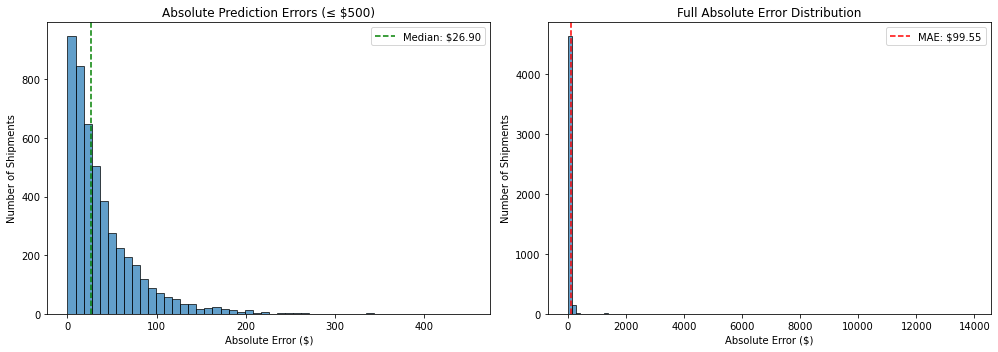

,Absolute Error ≤ ($),Shipments (%)
0,10,21.49
1,25,47.33
2,50,71.77
3,100,90.71
4,200,97.69
5,500,98.43


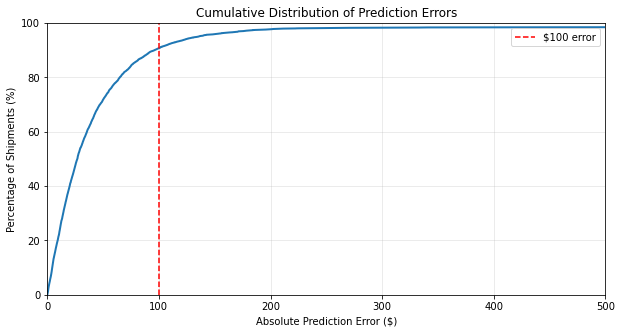

In [57]:
# Final chronological robustness check

train_oct = train[
    train["date"] < "2025-10-01"
].copy()

val_oct = train[
    (train["date"] >= "2025-10-01") &
    (train["date"] <= "2025-10-31")
].copy()

print("Training samples:", len(train_oct))
print("Validation samples:", len(val_oct))

print("Training period:",
      train_oct["date"].min(),
      "to",
      train_oct["date"].max())

print("Validation period:",
      val_oct["date"].min(),
      "to",
      val_oct["date"].max())

# Tuned hyperparameters from configuration 7
tuned_params = {
    "objective": "regression_l1",
    "n_estimators": 1000,
    "learning_rate": 0.05,
    "num_leaves": 127,
    "max_depth": 12,
    "min_child_samples": 60,
    "reg_lambda": 0.0,
    "reg_alpha": 1.0,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1
}

tuned_model = LGBMRegressor(**tuned_params)

october_configs = {
    "Main - Original Geography": {
        "model": lightgbm_model,
        "features": base_features,
        "geographic": False,
        "december": False
    },

    "Main - Tuned Geography": {
        "model": tuned_model,
        "features": base_features + geographic_features,
        "geographic": True,
        "december": False
    },

    "December - Month + Weekday": {
        "model": lightgbm_model,
        "features": december_features + ["day_of_week"],
        "geographic": False,
        "december": True
    }
}

october_results = []
october_predictions = {}

for name, config in october_configs.items():

    print(f"Training: {name}")

    # Feature engineering
    if config["december"]:

        tr = prepare_december_features(train_oct)
        va = prepare_december_features(val_oct)

    else:

        tr = engineer_features_v2(
            train_oct,
            add_geographic=config["geographic"],
            weight_strategy="missing"
        )

        va = engineer_features_v2(
            val_oct,
            add_geographic=config["geographic"],
            weight_strategy="missing"
        )

    features = config["features"]

    X_train = tr[features].copy()
    X_val = va[features].copy()

    # Categorical preprocessing
    for col in categorical_features:

        X_train[col] = X_train[col].astype("category")

        X_val[col] = pd.Categorical(
            X_val[col],
            categories=X_train[col].cat.categories
        )

    # Weighted RPM training
    y_train = tr["posted_rate"] / tr["distance"]

    sample_weights = tr["distance"]

    y_val = va["posted_rate"]

    # Train
    model = clone(config["model"])

    model.fit(
        X_train,
        y_train,
        sample_weight=sample_weights,
        categorical_feature=categorical_features
    )

    # Predict total freight rate
    predictions = (
        model.predict(X_val) *
        va["distance"].to_numpy()
    )

    # Evaluate
    metrics = evaluate(y_val, predictions)

    october_results.append({
        "Model": name,
        **metrics,
        "Non-positive": int((predictions <= 0).sum())
    })

    # Save predictions for further analysis
    october_predictions[name] = pd.DataFrame({
        "actual": y_val.to_numpy(),
        "predicted": predictions,
        "distance": va["distance"].to_numpy()
    })

october_results = pd.DataFrame(october_results)

display(
    october_results.sort_values("MAE").round(2)
)

main_models = [
    "Main - Original Geography",
    "Main - Tuned Geography"
]

best_main_name = (
    october_results[
        october_results["Model"].isin(main_models)
    ]
    .sort_values("MAE")
    .iloc[0]["Model"]
)

print("Best main model:", best_main_name)

error_df = october_predictions[best_main_name].copy()

# Calculate prediction errors
error_df["error"] = (
    error_df["predicted"] - error_df["actual"]
)

error_df["absolute_error"] = error_df["error"].abs()

absolute_errors = error_df["absolute_error"]

error_stats = {
    "MAE": absolute_errors.mean(),
    "Median AE": absolute_errors.median(),
    "75th percentile": absolute_errors.quantile(0.75),
    "90th percentile": absolute_errors.quantile(0.90),
    "95th percentile": absolute_errors.quantile(0.95),
    "99th percentile": absolute_errors.quantile(0.99),
    "Maximum error": absolute_errors.max()
}

display(
    pd.DataFrame(
        error_stats.items(),
        columns=["Metric", "Value ($)"]
    ).round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# -----------------------------------
# Plot 1: Typical prediction errors
# -----------------------------------

axes[0].hist(
    absolute_errors[absolute_errors <= 500],
    bins=50,
    edgecolor="black",
    alpha=0.7
)

axes[0].axvline(
    absolute_errors.median(),
    color="green",
    linestyle="--",
    label=f"Median: ${absolute_errors.median():.2f}"
)

axes[0].set_title("Absolute Prediction Errors (≤ $500)")
axes[0].set_xlabel("Absolute Error ($)")
axes[0].set_ylabel("Number of Shipments")
axes[0].legend()


# -----------------------------------
# Plot 2: Full error distribution
# -----------------------------------

axes[1].hist(
    absolute_errors,
    bins=100,
    edgecolor="black",
    alpha=0.7
)

axes[1].axvline(
    absolute_errors.mean(),
    color="red",
    linestyle="--",
    label=f"MAE: ${absolute_errors.mean():.2f}"
)

axes[1].set_title("Full Absolute Error Distribution")
axes[1].set_xlabel("Absolute Error ($)")
axes[1].set_ylabel("Number of Shipments")
axes[1].legend()

plt.tight_layout()
plt.show()

thresholds = [10, 25, 50, 100, 200, 500]

accuracy_table = pd.DataFrame({
    "Absolute Error ≤ ($)": thresholds,
    "Shipments (%)": [
        (absolute_errors <= t).mean() * 100
        for t in thresholds
    ]
})

display(accuracy_table.round(2))

sorted_errors = np.sort(absolute_errors)

cumulative_percentage = (
    np.arange(1, len(sorted_errors) + 1)
    / len(sorted_errors)
    * 100
)

plt.figure(figsize=(10, 5))

plt.plot(
    sorted_errors,
    cumulative_percentage,
    linewidth=2
)

plt.xlim(0, 500)
plt.ylim(0, 100)

plt.axvline(
    100,
    linestyle="--",
    color="red",
    label="$100 error"
)

plt.xlabel("Absolute Prediction Error ($)")
plt.ylabel("Percentage of Shipments (%)")
plt.title("Cumulative Distribution of Prediction Errors")

plt.grid(alpha=0.3)
plt.legend()
plt.show()



In [58]:
# Sort absolute prediction errors
sorted_errors = np.sort(
    error_df["absolute_error"].to_numpy()
)[::-1]

total_error = sorted_errors.sum()

contributions = []

for percentage in [0.5, 1, 2, 5, 10]:

    n = max(
        1,
        int(np.ceil(len(sorted_errors) * percentage / 100))
    )

    error_contribution = (
        sorted_errors[:n].sum() / total_error * 100
    )

    contributions.append({
        "Worst predictions (%)": percentage,
        "Number of shipments": n,
        "Share of total absolute error (%)": error_contribution
    })

contribution_df = pd.DataFrame(contributions)

display(contribution_df.round(2))

# Identify actual extreme-rate shipments
error_df["actual_rpm"] = (
    error_df["actual"] / error_df["distance"]
)

error_df["extreme_rate"] = (
    (error_df["actual_rpm"] < 1.0) |
    (error_df["actual_rpm"] > 5.0)
)

# Inspect the 20 largest prediction errors
display(
    error_df.sort_values(
        "absolute_error",
        ascending=False
    ).head(20)
)

,Worst predictions (%),Number of shipments,Share of total absolute error (%)
0,0.5,25,41.02
1,1.0,49,55.17
2,2.0,98,62.60
3,5.0,243,67.57
4,10.0,486,73.23


,actual,predicted,distance,error,absolute_error,actual_rpm,extreme_rate
392,17514.11,3643.083048,1893.0,-13871.026952,13871.026952,9.252039,True
3066,17893.17,4290.403701,2023.4,-13602.766299,13602.766299,8.843120,True
4151,19110.30,6035.910016,2979.1,-13074.389984,13074.389984,6.414790,True
3369,14784.38,3609.245019,1684.3,-11175.134981,11175.134981,8.777759,True
4389,15003.55,4888.989399,2782.4,-10114.560601,10114.560601,5.392305,True
3219,14403.14,4305.171683,2251.9,-10097.968317,10097.968317,6.395994,True
1120,14425.42,4424.061646,2492.6,-10001.358354,10001.358354,5.787298,True
155,13894.55,4554.700269,2083.1,-9339.849731,9339.849731,6.670131,True
237,11696.44,2357.334114,1187.0,-9339.105886,9339.105886,9.853783,True
4439,11596.28,2938.285675,1383.3,-8657.994325,8657.994325,8.383055,True


In [59]:
import sys

print(sys.executable)

C:\Users\Ademe\anaconda3\python.exe
